# 03 · The randomised offer experiment (simulator validation)

Notebooks 01–02 showed that the real campaigns were not randomised, so their effect can't be measured cleanly. This notebook validates the **simulated randomised experiment** built on top of the real members (`src/nectar/simulate/simulator.py`):

- **Who:** 2,407 members who shopped in the 26 weeks before the offer window.
- **What:** 18 Nectar-style category offers (10%, 20% or 30% off) valid for 4 weeks (weeks 92–95).
- **Assignment:** every (member, offer) pair is independently assigned to offer or control, 50/50.
- **Features:** computed only from weeks 17–91, before the offer window. A test checks that they don't change when later data is removed.
- **Ground truth:** the true uplift of each pair is known (`gt_` columns), so later models can be graded against it.

Four checks:
1. Does the control group behave like the real members did?
2. Is the randomisation balanced?
3. Does a simple A/B comparison recover the true average effect?
4. What does the true uplift look like, and why does targeting by propensity fail?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from nectar import viz
from nectar.viz import BLUE, ORANGE, GREY, TEXT_2
from nectar.simulate.simulator import SimConfig, simulate, PERSUADABILITY_WEIGHTS

viz.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
cfg = SimConfig()
df, diag = simulate(cfg)
pd.Series({k: v for k, v in diag.items() if k != "config"})

real_purchase_rate                  0.315
baseline_mean_p0                    0.315
baseline_cv_auc                     0.837
rows                           43,326.000
members                         2,407.000
offers                             18.000
persuadability_intercept           -5.044
mean_true_uplift                    0.040
share_negative_profit_uplift        0.808
dtype: float64

In [2]:
pd.Series(diag["config"]).to_frame("value")

,value
cutoff_week,92.000
window_weeks,4.000
treat_share,0.500
target_mean_uplift,0.040
margin,0.300
supplier_funding,0.500
stock_up_per_discount,0.500
spend_noise_sigma,0.400
member_effect_sd,0.500
seed,42.000


## 1. Does the control group behave like the real members?

The baseline (no-offer) purchase probability is a logistic regression fitted to what members **really** bought in weeks 92–95. Its cross-validated AUC is shown above. Below, the simulated control group's purchase rate is compared with the real purchase rate, offer by offer.

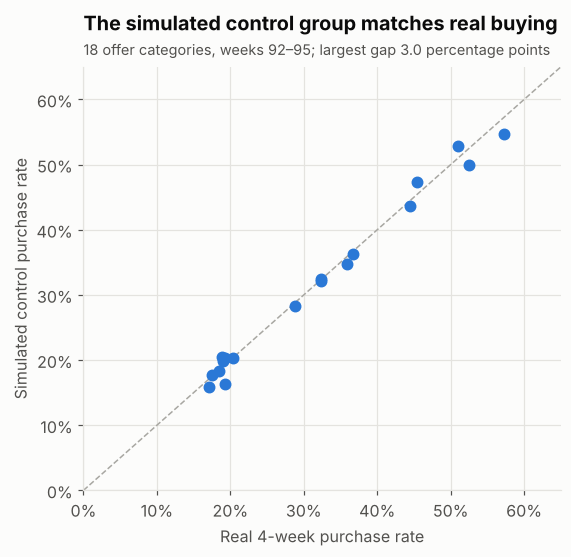

In [3]:
offer_names = df.drop_duplicates("offer_id").set_index("offer_id").commodity.str.title()
cal = df[df.treatment == 0].groupby("offer_id").agg(
    simulated=("purchased", "mean"), real=("real_purchased", "mean"), n=("purchased", "size"))
cal["commodity"] = offer_names
max_gap = (cal.simulated - cal.real).abs().max()

fig, ax = plt.subplots(figsize=(5.6, 5.0))
ax.plot([0, 0.65], [0, 0.65], color=GREY, lw=1, ls="--")
ax.scatter(cal.real, cal.simulated, s=46, color=BLUE, zorder=3)
ax.set_xlim(0, 0.65); ax.set_ylim(0, 0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Real 4-week purchase rate"); ax.set_ylabel("Simulated control purchase rate")
ax.grid(axis="x")
ax.set_title("The simulated control group matches real buying")
viz.subtitle(ax, f"18 offer categories, weeks 92–95; largest gap {max_gap * 100:.1f} percentage points")
viz.save(fig, "11_simulator_calibration"); fig

## 2. Is the randomisation balanced?

In [4]:
cols = ["m_spend_per_week", "m_trips_per_week", "m_member_discount_rate", "c_trip_share",
        "c_weeks_since_last", "c_discount_line_share", "discount_pct"]
t, c = df[df.treatment == 1], df[df.treatment == 0]
balance = pd.DataFrame({
    "offer_mean": t[cols].mean(),
    "control_mean": c[cols].mean(),
    "std_mean_diff": (t[cols].mean() - c[cols].mean()) / np.sqrt((t[cols].var() + c[cols].var()) / 2),
})
print(f"Offer group: {len(t):,} pairs | control group: {len(c):,} pairs")
balance

Offer group: 21,486 pairs | control group: 21,840 pairs


,offer_mean,control_mean,std_mean_diff
m_spend_per_week,32.358,32.709,-0.011
m_trips_per_week,1.108,1.123,-0.012
m_member_discount_rate,0.158,0.159,-0.003
c_trip_share,0.128,0.128,-0.003
c_weeks_since_last,25.694,25.528,0.006
c_discount_line_share,0.460,0.458,0.008
discount_pct,0.200,0.200,-0.009


All standardised mean differences are far below the usual 0.1 threshold: the two groups are comparable.

## 3. Does a simple A/B comparison recover the truth?

In [5]:
def diff_in_means(col):
    a, b = t[col], c[col]
    est = a.mean() - b.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    return est, est - 1.96 * se, est + 1.96 * se

rows = []
for col, truth, label in [("purchased", df.gt_uplift.mean(), "Conversion uplift (share)"),
                          ("gross_profit", df.gt_profit_uplift.mean(), "Profit uplift ($ per offer sent)")]:
    est, lo, hi = diff_in_means(col)
    rows.append({"metric": label, "true": truth, "A/B estimate": est, "95% CI low": lo, "95% CI high": hi,
                 "truth inside CI": lo <= truth <= hi})
pd.DataFrame(rows).set_index("metric")

,true,A/B estimate,95% CI low,95% CI high,truth inside CI
metric,,,,,
Conversion uplift (share),0.040,0.042,0.033,0.051,True
Profit uplift ($ per offer sent),-0.095,-0.106,-0.128,-0.085,True


The randomised A/B comparison recovers both true averages within their confidence intervals. On average the offers **do** lift purchases by about 4 points, but they **lose money**: sending every offer to everyone costs more in discount than the extra sales earn. Whether offers pay depends entirely on *who* gets them.

## 4. What the true uplift looks like

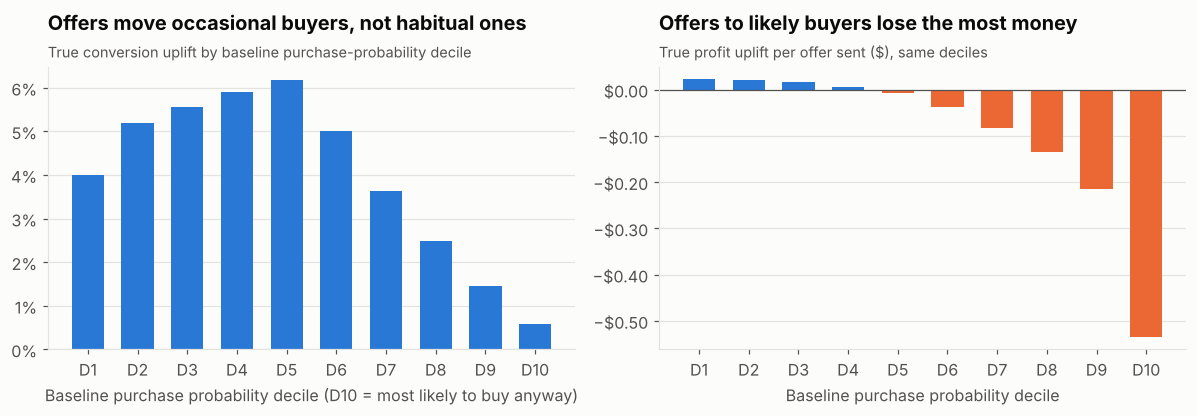

In [6]:
df["p0_decile"] = pd.qcut(df.gt_p0, 10, labels=[f"D{i}" for i in range(1, 11)])
by_dec = df.groupby("p0_decile", observed=True).agg(
    mean_p0=("gt_p0", "mean"), uplift=("gt_uplift", "mean"), profit_uplift=("gt_profit_uplift", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
x = np.arange(10)
ax = axes[0]
ax.bar(x, by_dec.uplift, color=BLUE, width=0.65)
ax.set_xticks(x, by_dec.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("Offers move occasional buyers, not habitual ones")
viz.subtitle(ax, "True conversion uplift by baseline purchase-probability decile")
ax.set_xlabel("Baseline purchase probability decile (D10 = most likely to buy anyway)")

ax = axes[1]
colors = [BLUE if v > 0 else ORANGE for v in by_dec.profit_uplift]
ax.bar(x, by_dec.profit_uplift, color=colors, width=0.65)
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.set_xticks(x, by_dec.index)
ax.yaxis.set_major_formatter(viz.money(2))
ax.set_title("Offers to likely buyers lose the most money")
viz.subtitle(ax, "True profit uplift per offer sent ($), same deciles")
ax.set_xlabel("Baseline purchase probability decile")
fig.tight_layout()
viz.save(fig, "12_uplift_by_propensity"); fig

In [7]:
by_dec

,mean_p0,uplift,profit_uplift
p0_decile,,,
D1,0.022,0.040,0.022
D2,0.047,0.052,0.022
D3,0.080,0.055,0.016
D4,0.128,0.059,0.006
D5,0.196,0.062,-0.007
D6,0.285,0.050,-0.038
D7,0.395,0.036,-0.083
D8,0.520,0.025,-0.135
D9,0.658,0.014,-0.215


### The four classic response types

Using the ground truth, every (member, offer) pair can be labelled. Thresholds are for illustration only:

- **Sure things:** likely to buy anyway (p0 ≥ 50%).
- **Persuadables:** the offer adds at least 5 points of purchase probability.
- **Lost causes:** unlikely to buy either way (p1 < 10%).
- **Marginal:** everything else.

In [8]:
def response_type(r):
    if r.gt_p0 >= 0.5:
        return "Sure things"
    if r.gt_uplift >= 0.05:
        return "Persuadables"
    if r.gt_p1 < 0.10:
        return "Lost causes"
    return "Marginal"

df["response_type"] = df.apply(response_type, axis=1)
types = df.groupby("response_type").agg(
    pairs=("gt_uplift", "size"), mean_p0=("gt_p0", "mean"), mean_uplift=("gt_uplift", "mean"),
    profit_uplift_per_pair=("gt_profit_uplift", "mean"), total_profit_uplift=("gt_profit_uplift", "sum"))
types["share_of_pairs"] = types.pairs / types.pairs.sum()
types.loc[["Persuadables", "Marginal", "Lost causes", "Sure things"]]

,pairs,mean_p0,mean_uplift,profit_uplift_per_pair,total_profit_uplift,share_of_pairs
response_type,,,,,,
Persuadables,7153,0.174,0.179,0.073,524.434,0.165
Marginal,15339,0.265,0.014,-0.060,-927.297,0.354
Lost causes,9379,0.044,0.009,-0.006,-52.742,0.216
Sure things,11455,0.690,0.013,-0.318,"-3,641.830",0.264


## 5. Why targeting by propensity fails, and the prize for getting it right

A typical first approach scores each member on *how likely they are to buy* and sends offers to the top of the list. The chart compares the **true** cumulative profit from sending offers to the top-k% of pairs ranked three ways:

- **Perfect uplift ranking** (ranked by true profit uplift): the ceiling that uplift models aim for.
- **Propensity ranking** (ranked by the baseline purchase probability): what a "likely buyer" model would do.
- **Random:** blanket offers to a random k%.

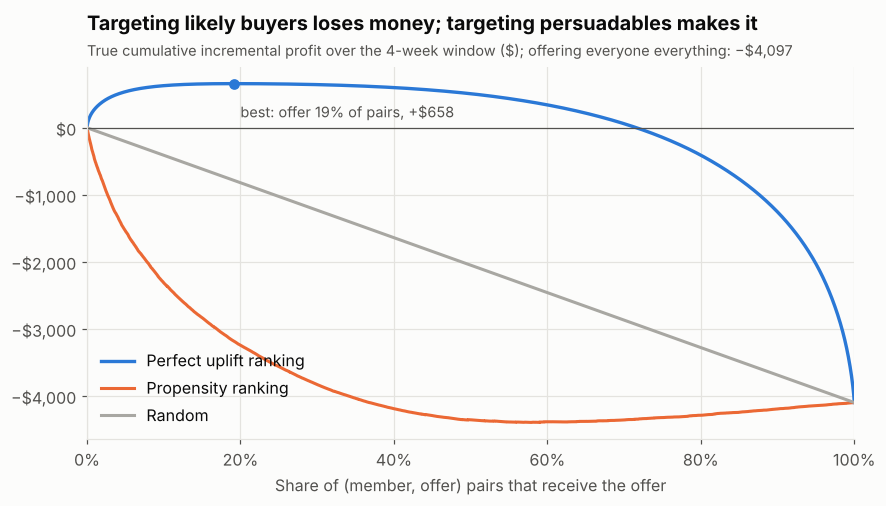

In [9]:
n = len(df)
k = np.arange(1, n + 1) / n
curves = {
    "Perfect uplift ranking": df.gt_profit_uplift.sort_values(ascending=False).cumsum().to_numpy(),
    "Propensity ranking": df.sort_values("gt_p0", ascending=False).gt_profit_uplift.cumsum().to_numpy(),
    "Random": k * df.gt_profit_uplift.sum(),
}
best_k = curves["Perfect uplift ranking"].argmax()
peak = curves["Perfect uplift ranking"][best_k]
blanket = df.gt_profit_uplift.sum()

fig, ax = plt.subplots(figsize=(9, 4.4))
for (name, y), col in zip(curves.items(), [BLUE, ORANGE, GREY]):
    ax.plot(k, y, color=col, label=name, lw=2.2 if col == BLUE else 2)
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.scatter([k[best_k]], [peak], color=BLUE, s=36, zorder=3)
ax.annotate(f"best: offer {k[best_k]:.0%} of pairs, +${peak:,.0f}", (k[best_k], peak),
            xytext=(4, -22), textcoords="offset points", fontsize=9.5, color=TEXT_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(viz.money(0))
ax.set_xlabel("Share of (member, offer) pairs that receive the offer")
ax.set_xlim(0, 1)
ax.grid(axis="x")
ax.set_title("Targeting likely buyers loses money; targeting persuadables makes it")
viz.subtitle(ax, f"True cumulative incremental profit over the 4-week window ($); offering everyone everything: −${-blanket:,.0f}")
ax.legend(loc="lower left")
viz.save(fig, "13_targeting_economics"); fig

In [10]:
at = lambda name, share: curves[name][int(share * n) - 1]
summary = pd.DataFrame({
    share: {name: at(name, share) for name in curves} for share in [0.1, 0.2, 0.3, 0.5, 1.0]
})
summary.columns = [f"top {int(s*100)}%" for s in summary.columns]
summary.style.format(lambda v: f"{'−' if v < 0 else ''}${abs(v):,.0f}")

,top 10%,top 20%,top 30%,top 50%,top 100%
Perfect uplift ranking,$628,$658,$644,$508,"−$4,097"
Propensity ranking,"−$2,313","−$3,243","−$3,829","−$4,355","−$4,097"
Random,−$410,−$819,"−$1,229","−$2,049","−$4,097"


## Summary

| Check | Result |
|---|---|
| Baseline realism | Control purchase rates match real weeks 92–95 behaviour offer by offer; baseline AUC ≈ 0.84 |
| Randomisation | All standardised mean differences < 0.05 |
| A/B recovery | Difference in means recovers the true conversion and profit uplift within the 95% CI |
| Effect shape | Uplift is highest for occasional buyers and near zero for habitual ones |
| Economics | Blanket offers lose money; a perfect uplift ranking turns the same budget profitable; a propensity ranking does worse than random |

**Next (weeks 4–6):** feature pipeline with validation, then propensity, T-learner, X-learner, DR-learner and causal forest models trained on the observable columns only, and graded against the `gt_` ground truth and the oracle curve above.